# 01 · Basic EDA: Causal Pricing Starter Dataset

**Owner:** Fatima (Data collection, quality, cleaning, basic EDA) · **Status:** development notebook

> **Data status: SIMULATED.** The starter dataset is simulated development data (see `data/raw/README_DATASET.md`). Every chart and number below describes the *simulated* data and must be labelled simulation/demo until the mentor confirms that simulated data is acceptable.
>
> **Associations, not causes.** This notebook only describes patterns. A chart cannot prove that a price change *caused* a change in sales; that is the job of the causal design and Synthetic Control work.

**Input:** `data/processed/cleaned_*.csv` (produced by `src/clean_pricing_data.py`; raw files are untouched).
**Run from:** the `notebooks/` folder. Charts are also saved to `docs/figures/`.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12, 'axes.labelsize': 10})
COL = {'treated': '#C0392B', 'control': '#2E86C1'}

DATA = Path('../data/processed')
FIGS = Path('../docs/figures'); FIGS.mkdir(parents=True, exist_ok=True)

txn = pd.read_csv(DATA / 'cleaned_regional_market_transactions.csv', parse_dates=['date', 'treatment_date'], low_memory=False)
mkt = pd.read_csv(DATA / 'cleaned_market_metadata.csv', parse_dates=['treatment_date'])
prd = pd.read_csv(DATA / 'cleaned_product_metadata.csv')

# helper columns used only for analysis (not saved back to the data)
txn['month'] = txn['date'].dt.month
txn['post_period'] = (txn['date'] >= '2024-07-01').astype(int)     # calendar: on/after 1 July 2024
txn['group'] = np.where(txn['treated_market'] == 1, 'treated', 'control')
txn = txn.merge(prd[['product_id', 'base_price']], on='product_id', how='left')
txn['price_ratio'] = txn['price'] / txn['base_price']              # price relative to the product's baseline

print('transactions:', txn.shape, '| markets:', mkt.shape, '| products:', prd.shape)

transactions: (87600, 25) | markets: (20, 5) | products: (12, 4)


## 1. Data overview
**Unit of analysis:** one row = one *product* in one *market* on one *day* (market-product-day).

In [2]:
print('Unit of analysis check -> rows:', len(txn), '= markets x products x days =',
      txn.market_id.nunique(), 'x', txn.product_id.nunique(), 'x', txn.date.nunique())
print('Date range:', txn.date.min().date(), 'to', txn.date.max().date())
print('Duplicate market+product+date rows:', txn.duplicated(['market_id','product_id','date']).sum())
print('Treated markets:', sorted(txn.loc[txn.treated_market==1,'market_id'].unique()),
      '| treatment date:', txn.treatment_date.dropna().unique()[0].date())
print()
print('Share of rows by group x period (calendar):')
print(pd.crosstab(txn.group, txn.post_period, margins=True).to_string())
print()
print('Missing values still present after cleaning:')
miss = txn[['competitor_price','promotion','treatment_date']].isna().sum()
print(miss.to_string())
print('(treatment_date is blank for control markets by design; competitor_price and promotion are flagged, not imputed.)')
print()
print(txn[['price','competitor_price','units_sold','revenue','unit_cost','gross_profit']].describe().round(2).T.to_string())

Unit of analysis check -> rows: 87600 = markets x products x days = 20 x 12 x 365
Date range: 2024-01-01 to 2024-12-30
Duplicate market+product+date rows: 0
Treated markets: ['M001', 'M002', 'M003', 'M004'] | treatment date: 2024-07-01

Share of rows by group x period (calendar):
post_period      0      1    All
group                           
control      34944  35136  70080
treated       8736   8784  17520
All          43680  43920  87600

Missing values still present after cleaning:
competitor_price       60
promotion              30
treatment_date      70080
(treatment_date is blank for control markets by design; competitor_price and promotion are flagged, not imputed.)

                    count     mean      std     min     25%      50%      75%       max
price             87600.0    32.58    21.56    8.20   14.67    21.78    49.90     79.70
competitor_price  87540.0    33.07    21.96    7.69   14.78    21.88    50.70     87.28
units_sold        87600.0    73.55    26.37   21.00

**Observations**
- The panel is complete: 20 markets × 12 products × 365 days = 87,600 rows, with no repeated market-product-day.
- Treated markets are M001–M004 with treatment starting 2024-07-01. Treated-market rows are 20% of the data; rows where the price rise is actually active (`treatment = 1`) are about 10%.
- Remaining gaps are small and flagged: 60 competitor prices and 30 promotion values. `treatment_date` is blank only for control markets.

## 2. Sales and revenue over time

 month    revenue  units  gross_profit  avg_price
     1 18544054.0 570297     7043477.0      32.36
     2 18178047.0 558470     6913753.0      32.32
     3 20055087.0 616690     7606254.0      32.30
     4 19427012.0 597218     7363638.0      32.33
     5 19361128.0 594953     7349263.0      32.31
     6 17879372.0 550464     6780730.0      32.34
     7 17358582.0 525783     6605740.0      32.85
     8 16308307.0 493284     6204372.0      32.84
     9 15379567.0 465802     5844221.0      32.82
    10 15830889.0 479415     6014514.0      32.83
    11 15825836.0 479548     6002181.0      32.85
    12 16855330.0 510630     6412755.0      32.83


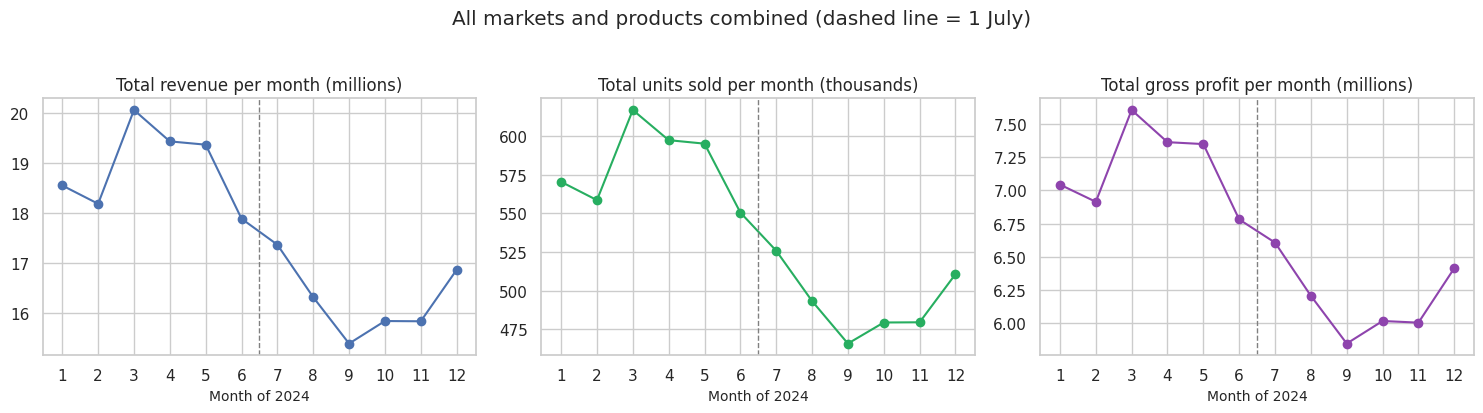

In [3]:
monthly = txn.groupby('month').agg(revenue=('revenue','sum'), units=('units_sold','sum'),
                                   gross_profit=('gross_profit','sum'), avg_price=('price','mean')).reset_index()
print(monthly.assign(revenue=lambda d: d.revenue.round(0), units=lambda d: d.units, gross_profit=lambda d: d.gross_profit.round(0),
                     avg_price=lambda d: d.avg_price.round(2)).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(monthly.month, monthly.revenue/1e6, marker='o'); ax[0].set_title('Total revenue per month (millions)')
ax[1].plot(monthly.month, monthly.units/1e3, marker='o', color='#27AE60'); ax[1].set_title('Total units sold per month (thousands)')
ax[2].plot(monthly.month, monthly.gross_profit/1e6, marker='o', color='#8E44AD'); ax[2].set_title('Total gross profit per month (millions)')
for a in ax: a.set_xlabel('Month of 2024'); a.set_xticks(range(1,13)); a.axvline(6.5, ls='--', color='grey', lw=1)
fig.suptitle('All markets and products combined (dashed line = 1 July)', y=1.03)
fig.tight_layout(); fig.savefig(FIGS / 'fig01_monthly_totals.png', dpi=130, bbox_inches='tight'); plt.show()

**Interpretation (association only)**
- Revenue, units and gross profit all follow the same shape: a rise to a peak in March–April, a slide through the second half of the year, a low point in September–November and a small recovery in December.
- Total revenue is highest in March (about 20.1 million) and lowest in September (about 15.4 million).
- Because this combines treated and control markets, the second-half decline cannot be attributed to the price rise. The next sections separate the groups and the seasonal pattern.
- Note that 31 December is missing, so December has 30 days of data instead of 31.

Seasonal index identical across markets on a given day: True
Correlation, daily average units vs seasonal_index: 1.00

Average units by day of week:
day_of_week
Mon    77.0
Tue    76.0
Wed    72.6
Thu    70.2
Fri    70.2
Sat    72.8
Sun    75.9


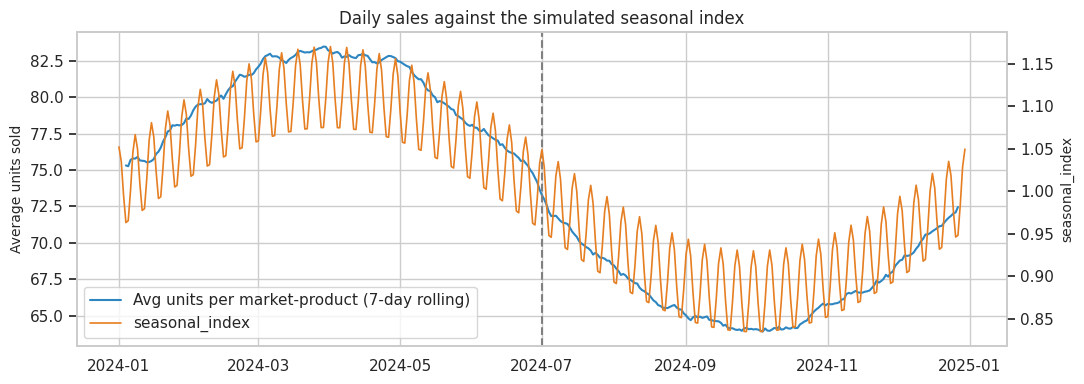

In [4]:
daily = txn.groupby('date').agg(units=('units_sold','mean'), seasonal_index=('seasonal_index','first')).reset_index()
daily['units_7d'] = daily.units.rolling(7, center=True).mean()
print('Seasonal index identical across markets on a given day:', txn.groupby('date').seasonal_index.nunique().max() == 1)
print('Correlation, daily average units vs seasonal_index: %.2f' % daily[['units','seasonal_index']].corr().iloc[0,1])

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.date, daily.units_7d, color='#2E86C1', label='Avg units per market-product (7-day rolling)')
ax.set_ylabel('Average units sold'); ax.set_title('Daily sales against the simulated seasonal index')
ax2 = ax.twinx(); ax2.plot(daily.date, daily.seasonal_index, color='#E67E22', lw=1.2, label='seasonal_index'); ax2.set_ylabel('seasonal_index'); ax2.grid(False)
ax.axvline(pd.Timestamp('2024-07-01'), ls='--', color='grey')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1+h2, l1+l2, loc='lower left')
fig.tight_layout(); fig.savefig(FIGS / 'fig02_units_vs_seasonality.png', dpi=130, bbox_inches='tight'); plt.show()

dow = txn.groupby('day_of_week').units_sold.mean().rename(index={0:'Mon',1:'Tue',2:'Wed',3:'Thu',4:'Fri',5:'Sat',6:'Sun'})
print(); print('Average units by day of week:'); print(dow.round(1).to_string())

**Interpretation**
- Daily average sales track the simulated `seasonal_index` almost perfectly (correlation about 1.00), so a large part of the rise and fall during the year is built-in seasonality, not a price effect.
- There is also a weekday pattern: average units are highest on Monday and Tuesday and lowest on Thursday and Friday. If a model uses weekly or daily data, `day_of_week` is worth including.

## 3. Treated markets versus control markets
Descriptive comparison only. Whether treated markets *would have* followed the controls without the price rise is the question for the Synthetic Control stage.

Pre-treatment monthly ratio, treated / control average units (1.00 = identical):
month
1    1.001
2    1.012
3    1.003
4    1.007
5    1.005
6    1.005


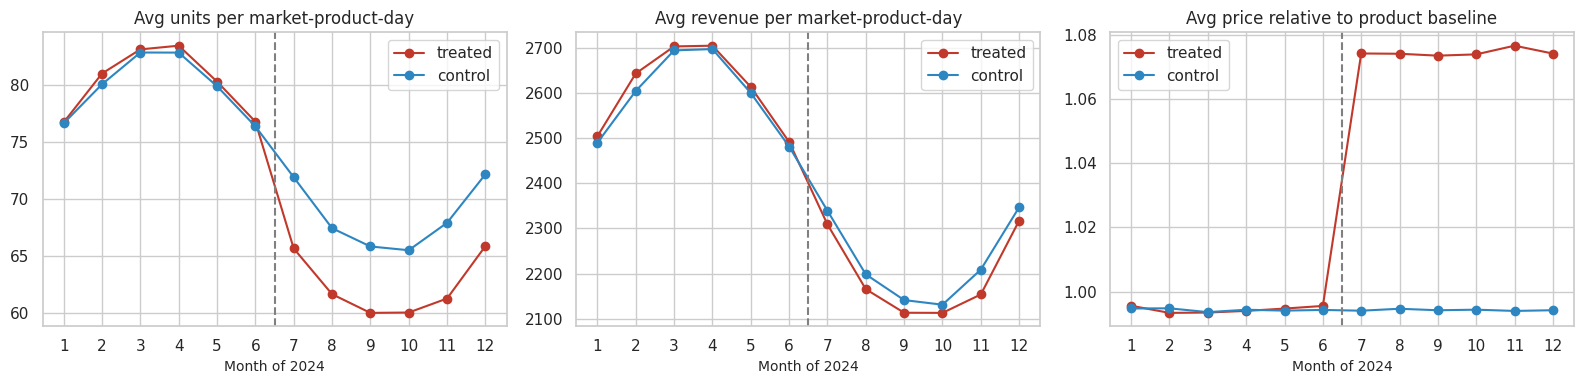

In [5]:
grp = txn.groupby(['month','group']).agg(units=('units_sold','mean'), revenue=('revenue','mean'), price_ratio=('price_ratio','mean')).reset_index()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for g, c in COL.items():
    d = grp[grp.group == g]
    ax[0].plot(d.month, d.units, marker='o', color=c, label=g)
    ax[1].plot(d.month, d.revenue, marker='o', color=c, label=g)
    ax[2].plot(d.month, d.price_ratio, marker='o', color=c, label=g)
ax[0].set_title('Avg units per market-product-day'); ax[1].set_title('Avg revenue per market-product-day'); ax[2].set_title('Avg price relative to product baseline')
for a in ax: a.axvline(6.5, ls='--', color='grey'); a.set_xlabel('Month of 2024'); a.set_xticks(range(1,13)); a.legend()
fig.tight_layout(); fig.savefig(FIGS / 'fig03_treated_vs_control.png', dpi=130, bbox_inches='tight'); plt.show()

pre = txn[txn.post_period==0].groupby(['month','group']).units_sold.mean().unstack()
print('Pre-treatment monthly ratio, treated / control average units (1.00 = identical):')
print((pre['treated']/pre['control']).round(3).to_string())

**Interpretation**
- Before July the treated and control lines sit almost on top of each other for units, revenue and price. The monthly treated-to-control ratio of units stays between about 1.00 and 1.01. That is a good sign for the comparison, but it is a visual check, not a formal test.
- From July the price line for treated markets steps up by roughly 8% while the control line does not move. Units and revenue fall in *both* groups (seasonality), but treated markets fall further.
- The price step matches the README, which confirms the treatment columns were read correctly.

In [6]:
summary = (txn.groupby(['group','post_period'])
              .agg(units=('units_sold','mean'), price=('price','mean'), revenue=('revenue','mean'), gross_profit=('gross_profit','mean'))
              .round(2))
print(summary.to_string())

u = txn.groupby(['group','post_period']).units_sold.mean().unstack()
change = u[1] - u[0]
print()
print('Change in average units, post minus pre (calendar split at 1 July):')
print(change.round(2).to_string())
print('Treated minus control change: %.2f units (%.1f%% of the treated pre-period average)' %
      (change['treated']-change['control'], 100*(change['treated']-change['control'])/u.loc['treated',0]))
r = txn.groupby(['group','post_period']).revenue.mean().unstack()
rchange = r[1] - r[0]
print('Treated minus control change in average revenue: %.1f per market-product-day (%.1f%% of the treated pre-period average)' %
      (rchange['treated']-rchange['control'], 100*(rchange['treated']-rchange['control'])/r.loc['treated',0]))
print()
print('Promotion share by group and period:')
print(txn.groupby(['group','post_period']).promotion.mean().round(3).unstack().to_string())

                     units  price  revenue  gross_profit
group   post_period                                     
control 0            79.77  32.32  2594.12        984.05
        1            68.47  32.31  2227.71        847.77
treated 0            80.21  32.33  2609.42        992.48
        1            62.45  34.93  2195.54        830.65

Change in average units, post minus pre (calendar split at 1 July):
group
control   -11.29
treated   -17.77
Treated minus control change: -6.47 units (-8.1% of the treated pre-period average)
Treated minus control change in average revenue: -47.5 per market-product-day (-1.8% of the treated pre-period average)

Promotion share by group and period:
post_period      0      1
group                    
control      0.083  0.082
treated      0.080  0.074


**Interpretation, with caution**
- Average units fell in both groups after 1 July, by about 11 units for controls and about 18 for treated markets.
- The raw gap between those two changes is about 6.5 units per market-product-day (about 8% of the treated pre-period level). For revenue the gap is much smaller, only about 2% of the pre-period level, because the higher price largely offsets the lost units. This is a **descriptive before/after difference only**. It is *not* a causal estimate: it ignores promotions, market size, differences between products and any other confounder, and it comes from simulated data.
- Promotion shares are similar across groups and periods (about 7–8%), so promotions alone do not obviously explain the gap, but this needs proper handling in the causal design.

## 4. Differences between markets and products

Correlation market_size_index vs avg units: 0.997

          avg_units  avg_revenue
region                          
Region_1       90.8       2978.2
Region_2       80.8       2647.4
Region_3       51.8       1701.1
Region_4       59.8       1969.9
Region_5       84.5       2747.0

market_id   region  market_size_index    revenue
     M001 Region_1                1.4 13304272.9
     M004 Region_4                1.3 12241205.2
     M002 Region_2                1.0  9601890.8
     M003 Region_3                0.7  6934096.7


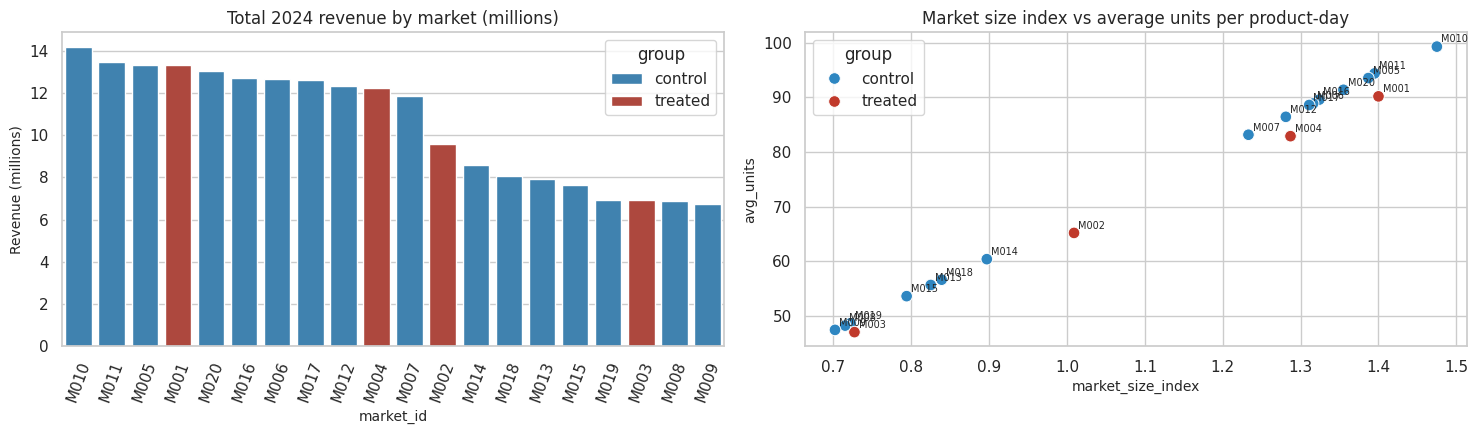

In [7]:
mk = (txn.groupby('market_id').agg(revenue=('revenue','sum'), avg_units=('units_sold','mean')).reset_index()
          .merge(mkt[['market_id','region','market_size_index','treated_market']], on='market_id').sort_values('revenue', ascending=False))
mk['group'] = np.where(mk.treated_market==1, 'treated', 'control')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=mk, x='market_id', y=mk.revenue/1e6, hue='group', palette=COL, dodge=False, ax=ax[0])
ax[0].set_title('Total 2024 revenue by market (millions)'); ax[0].set_ylabel('Revenue (millions)'); ax[0].tick_params(axis='x', rotation=70)
sns.scatterplot(data=mk, x='market_size_index', y='avg_units', hue='group', palette=COL, s=70, ax=ax[1])
for _, r in mk.iterrows(): ax[1].annotate(r.market_id, (r.market_size_index, r.avg_units), fontsize=7, xytext=(3,3), textcoords='offset points')
ax[1].set_title('Market size index vs average units per product-day')
fig.tight_layout(); fig.savefig(FIGS / 'fig04_markets.png', dpi=130, bbox_inches='tight'); plt.show()

print('Correlation market_size_index vs avg units: %.3f' % mk[['market_size_index','avg_units']].corr().iloc[0,1])
print()
print(txn.groupby('region').agg(avg_units=('units_sold','mean'), avg_revenue=('revenue','mean')).round(1).to_string())
print()
print(mk[mk.treated_market==1][['market_id','region','market_size_index','revenue']].round(1).to_string(index=False))

**Interpretation**
- Markets differ a lot in size. The largest (M010, M011, M005) earn about twice as much as the smallest (M009, M008, M003).
- Market size explains almost all of that (correlation about 0.997 between `market_size_index` and average units), so size must be considered when picking comparison markets.
- Regions differ too: Region_1 and Region_5 are large, Region_3 and Region_4 are small.
- The four treated markets are mixed in size: M001 is large (index 1.40), M004 is large (1.29), M002 is medium (1.01) and M003 is small (0.73). That is useful for donor selection, because no single control market is a perfect match for all four.

product_id   category  avg_price  avg_units  revenue  gross_profit  margin_pct
      P001 Category_1      17.81       74.2      9.6           3.7        38.1
      P002 Category_2      13.00       57.3      5.4           2.1        38.1
      P003 Category_3      16.61       85.1     10.3           3.9        38.0
      P004 Category_4      18.33       62.8      8.4           3.2        38.1
      P005 Category_1      37.61       99.7     27.3          10.4        38.0
      P006 Category_2      69.31       68.3     34.4          13.1        37.9
      P007 Category_3      43.15       81.9     25.7           9.7        37.9
      P008 Category_4      68.71       71.7     35.8          13.6        38.0
      P009 Category_1      25.95       50.5      9.5           3.6        38.0
      P010 Category_2       9.62       67.2      4.7           1.8        38.0
      P011 Category_3      59.03       75.0     32.2          12.2        38.0
      P012 Category_4      11.84       88.8      7.6

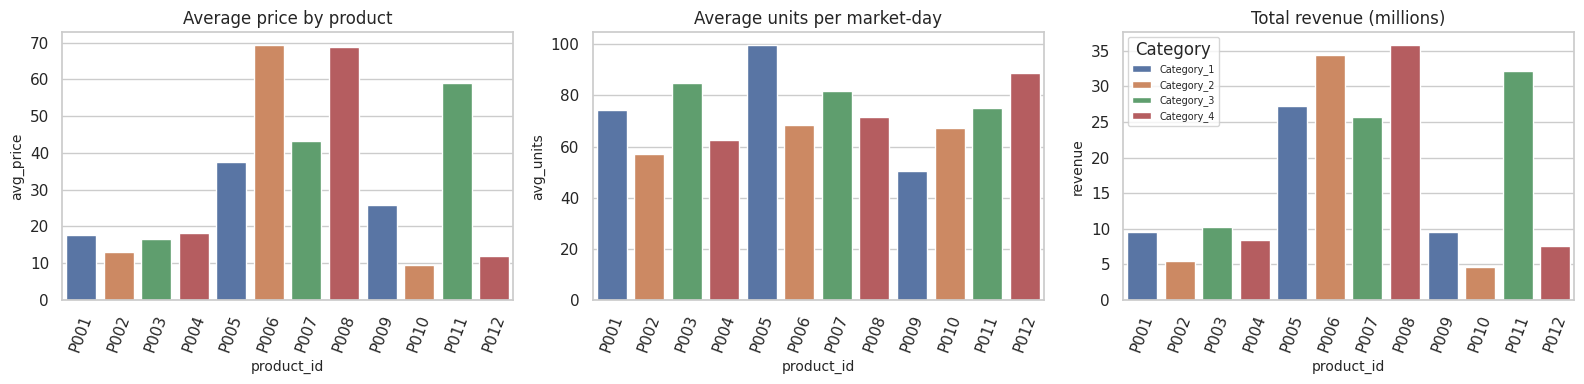

In [8]:
pr = (txn.groupby('product_id').agg(category=('category','first'), avg_price=('price','mean'), avg_units=('units_sold','mean'),
                                    revenue=('revenue','sum'), gross_profit=('gross_profit','sum')).reset_index())
pr['margin_pct'] = 100 * pr.gross_profit / pr.revenue
print(pr.assign(revenue=lambda d: (d.revenue/1e6).round(1), gross_profit=lambda d: (d.gross_profit/1e6).round(1),
                avg_price=lambda d: d.avg_price.round(2), avg_units=lambda d: d.avg_units.round(1), margin_pct=lambda d: d.margin_pct.round(1)).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=pr, x='product_id', y='avg_price', hue='category', dodge=False, ax=ax[0], legend=False); ax[0].set_title('Average price by product')
sns.barplot(data=pr, x='product_id', y='avg_units', hue='category', dodge=False, ax=ax[1], legend=False); ax[1].set_title('Average units per market-day')
sns.barplot(data=pr, x='product_id', y=pr.revenue/1e6, hue='category', dodge=False, ax=ax[2]); ax[2].set_title('Total revenue (millions)')
ax[2].legend(title='Category', fontsize=7)
for a in ax: a.tick_params(axis='x', rotation=70)
fig.tight_layout(); fig.savefig(FIGS / 'fig05_products.png', dpi=130, bbox_inches='tight'); plt.show()
print(); print('Gross margin overall: %.1f%%' % (100*txn.gross_profit.sum()/txn.revenue.sum()))

**Interpretation**
- Revenue is driven by price level much more than volume. The five most expensive products (P006, P008, P011, P007 and P005, with average prices of about 38–69) are also the five biggest earners (about 26–36 million each), even though cheaper products often sell as many or more units.
- Units sold per day are fairly similar across products (about 50–100), but prices range from about 10 to 69.
- Gross margin is about 38% overall and similar across products, because the simulated unit cost is a roughly constant share of price. Outcome choice (revenue or units sold) therefore matters: revenue changes are dominated by high-priced products.

## 5. Price versus sales
Prices differ a lot between products, so comparing raw prices with raw units mixes products together. Below, price is expressed relative to each product's own baseline (`price_ratio = price / base_price`).

Correlation, raw price ratio vs units: -0.27
Within market-product, all rows:       slope -2.54, correlation -0.59
... no-promotion rows only:           slope -1.90, correlation -0.43
... no promotion, control markets only: slope -1.27, correlation -0.25

            rows  avg_units  avg_price_ratio
promotion                                   
0.0        80448     71.559            1.008
1.0         7122     95.954            0.937


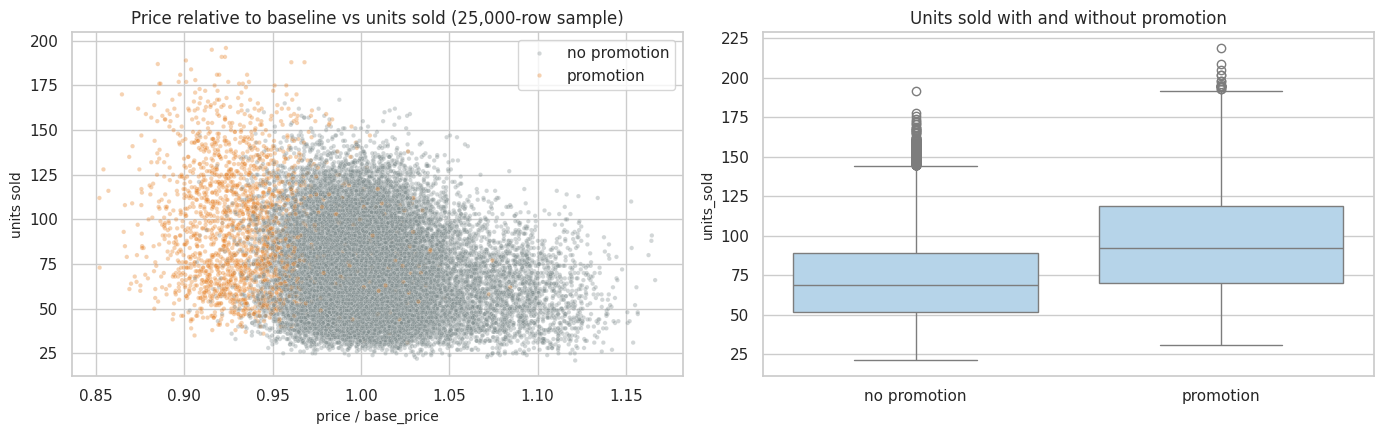

In [9]:
samp = txn.sample(25000, random_state=42)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=samp, x='price_ratio', y='units_sold', hue=samp.promotion.map({0:'no promotion', 1:'promotion'}),
                palette={'no promotion':'#7F8C8D', 'promotion':'#E67E22'}, alpha=0.35, s=10, ax=ax[0])
ax[0].set_title('Price relative to baseline vs units sold (25,000-row sample)'); ax[0].set_xlabel('price / base_price'); ax[0].set_ylabel('units sold'); ax[0].legend(title='')
sns.boxplot(data=txn.dropna(subset=['promotion']), x=txn.dropna(subset=['promotion']).promotion.map({0:'no promotion', 1:'promotion'}), y='units_sold', ax=ax[1], color='#AED6F1')
ax[1].set_title('Units sold with and without promotion'); ax[1].set_xlabel('')
fig.tight_layout(); fig.savefig(FIGS / 'fig06_price_vs_units.png', dpi=130, bbox_inches='tight'); plt.show()

d = txn.copy()
d['log_units'] = np.log(d.units_sold); d['log_price'] = np.log(d.price)
for c in ['log_units','log_price']:
    d[c+'_dm'] = d[c] - d.groupby(['market_id','product_id'])[c].transform('mean')   # compare each series with its own average
def slope(df): return np.polyfit(df.log_price_dm, df.log_units_dm, 1)[0], df.log_price_dm.corr(df.log_units_dm)
print('Correlation, raw price ratio vs units: %.2f' % txn.price_ratio.corr(txn.units_sold))
s_all = slope(d);                                      print('Within market-product, all rows:       slope %.2f, correlation %.2f' % s_all)
s_np  = slope(d[(d.promotion==0)]);                    print('... no-promotion rows only:           slope %.2f, correlation %.2f' % s_np)
s_c   = slope(d[(d.promotion==0)&(d.treated_market==0)]); print('... no promotion, control markets only: slope %.2f, correlation %.2f' % s_c)
print()
print(txn.groupby('promotion').agg(rows=('units_sold','size'), avg_units=('units_sold','mean'), avg_price_ratio=('price_ratio','mean')).round(3).to_string())

**Interpretation (association only)**
- Across the whole dataset, higher price relative to baseline goes with fewer units sold (correlation about −0.27), and promotions sit at lower prices with higher sales.
- Within the same market-product series, a 1% higher price goes with roughly 2.5% fewer units when all rows are used, about 1.9% fewer when promotion days are excluded, and about 1.3% fewer when treated markets are excluded as well. The size of the "price effect" changes a lot depending on what is controlled for, which is exactly why this chart **cannot** be read as a causal price elasticity.
- Promotion is a clear confounder: promoted days have prices about 7% lower than non-promoted days and sell about 34% more units (about 96 against 72). Any analysis that ignores promotion will overstate how much price alone moves sales.

Competitor gap (competitor_price / price - 1):
count    87540.000
mean         0.017
std          0.070
min         -0.264
25%         -0.031
50%          0.016
75%          0.064
max          0.325

Correlation, competitor gap vs units: 0.12


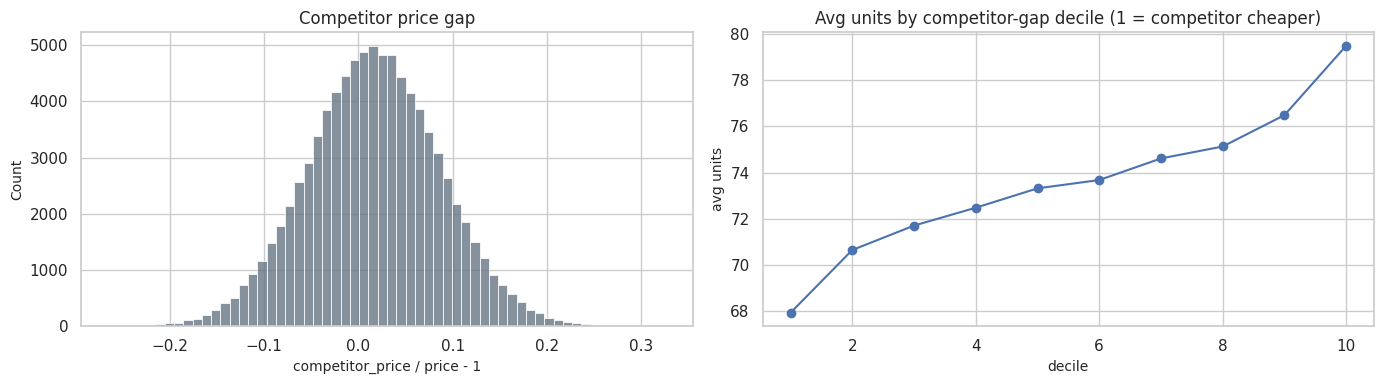

In [10]:
txn['competitor_gap'] = txn.competitor_price / txn.price - 1       # >0 means the competitor is more expensive than us
print('Competitor gap (competitor_price / price - 1):'); print(txn.competitor_gap.describe().round(3).to_string())
print('\nCorrelation, competitor gap vs units: %.2f' % txn.competitor_gap.corr(txn.units_sold))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(txn.competitor_gap.dropna(), bins=60, ax=ax[0], color='#5D6D7E'); ax[0].set_title('Competitor price gap'); ax[0].set_xlabel('competitor_price / price - 1')
bins = pd.qcut(txn.competitor_gap, 10)
bm = txn.groupby(bins, observed=True).units_sold.mean()
ax[1].plot(range(1, 11), bm.values, marker='o'); ax[1].set_title('Avg units by competitor-gap decile (1 = competitor cheaper)'); ax[1].set_xlabel('decile'); ax[1].set_ylabel('avg units')
fig.tight_layout(); fig.savefig(FIGS / 'fig07_competitor_gap.png', dpi=130, bbox_inches='tight'); plt.show()

**Interpretation**
- Our price is on average about 1.7% below the competitor's, and the gap stays roughly between −26% and +33%.
- Sales are higher when the competitor is relatively more expensive (weak positive correlation of about 0.12). Because the gap depends on our own price, which itself moves with promotions and the treatment, this is a rough association and not evidence of competitor effects.

## 6. Promotions

Overall promotion share: 8.1% of rows (missing excluded)
Share by month: [7.8, 8.4, 8.8, 8.4, 8.1, 7.8, 8.0, 7.6, 8.0, 8.2, 8.3, 8.2]

Promotion share by product:
product_id
P001    8.5
P002    8.3
P003    7.7
P004    8.1
P005    8.3
P006    8.1
P007    7.8
P008    7.6
P009    8.4
P010    8.2
P011    7.8
P012    8.8


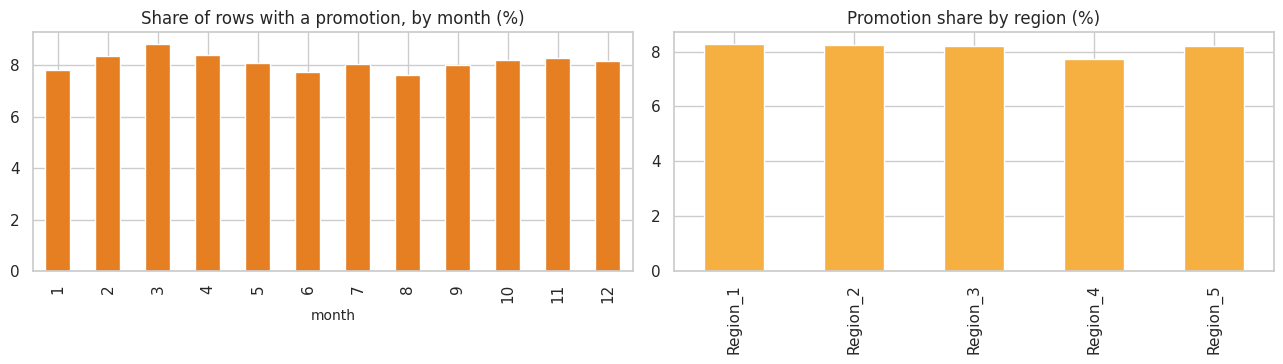

In [11]:
promo_m = txn.groupby('month').promotion.mean()
print('Overall promotion share: %.1f%% of rows (missing excluded)' % (100*txn.promotion.mean()))
print('Share by month:', (100*promo_m).round(1).tolist())
print(); print('Promotion share by product:'); print((100*txn.groupby('product_id').promotion.mean()).round(1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
(100*promo_m).plot(kind='bar', ax=ax[0], color='#E67E22'); ax[0].set_title('Share of rows with a promotion, by month (%)'); ax[0].set_xlabel('month')
(100*txn.groupby('region').promotion.mean()).plot(kind='bar', ax=ax[1], color='#F5B041'); ax[1].set_title('Promotion share by region (%)'); ax[1].set_xlabel('')
fig.tight_layout(); fig.savefig(FIGS / 'fig08_promotions.png', dpi=130, bbox_inches='tight'); plt.show()

**Interpretation**
- About 8% of market-product-days have a promotion, spread fairly evenly across months, regions and products. There is no obvious pile-up of promotions in the treated markets or after July, which is reassuring for the comparison.
- Promotion should still be treated as a covariate in any model, given its strong link with price and units.

## 7. Distributions and unusual values

Values more than 4 standard deviations from their product mean: {'price': 10, 'competitor_price': 8, 'units_sold': 8, 'unit_cost': 0, 'revenue': 1} -> total 27
Max units_sold: 219 (product-day maximum); share of rows above 150 units: 0.68%


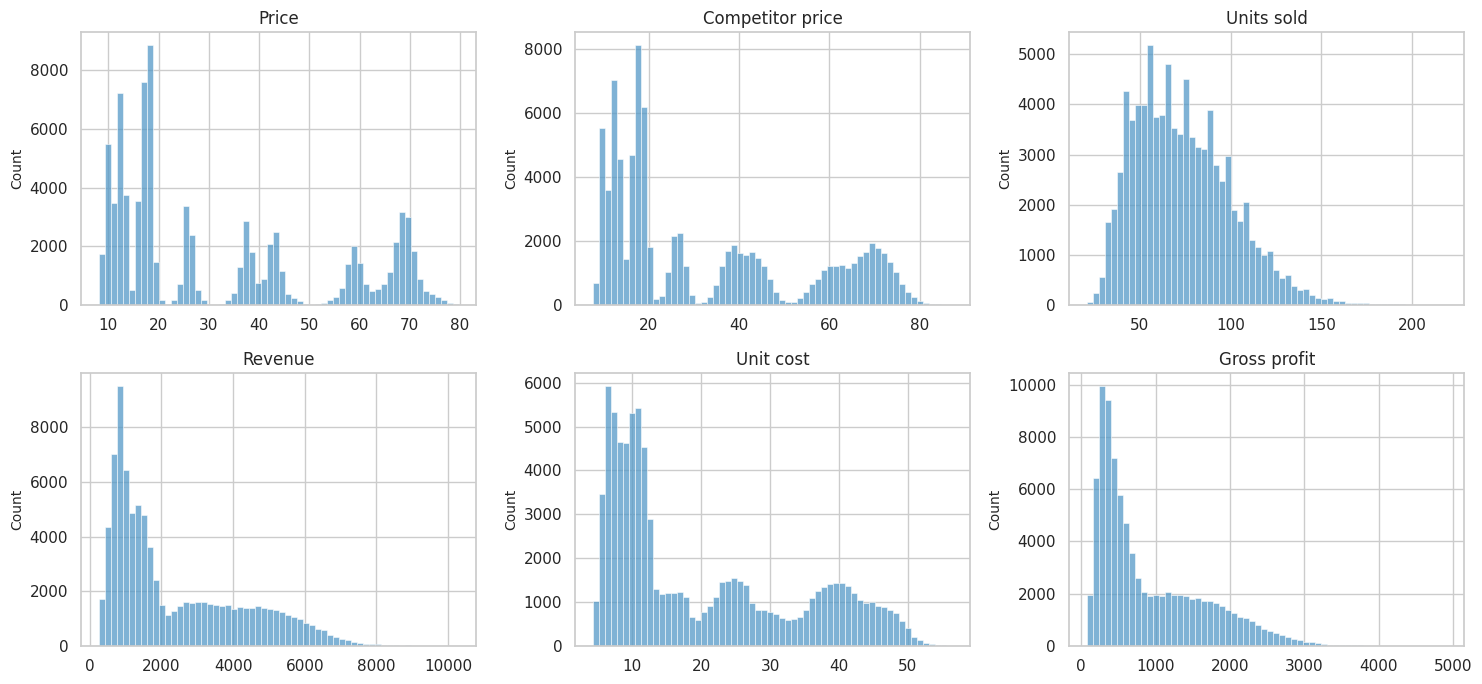

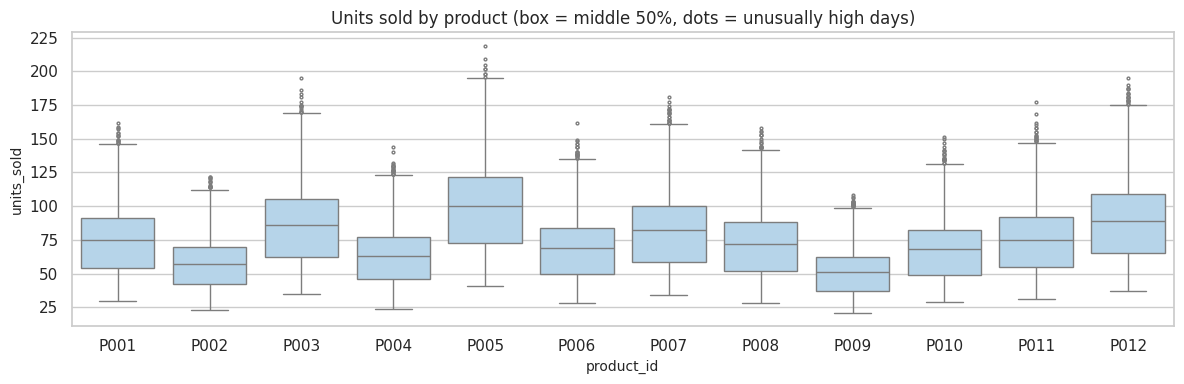

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, (col, title) in zip(ax.ravel(), [('price','Price'),('competitor_price','Competitor price'),('units_sold','Units sold'),
                                         ('revenue','Revenue'),('unit_cost','Unit cost'),('gross_profit','Gross profit')]):
    sns.histplot(txn[col].dropna(), bins=60, ax=a, color='#5499C7'); a.set_title(title); a.set_xlabel('')
fig.tight_layout(); fig.savefig(FIGS / 'fig09_distributions.png', dpi=130, bbox_inches='tight'); plt.show()

z_rows = {}
for c in ['price','competitor_price','units_sold','unit_cost','revenue']:
    g = txn.groupby('product_id')[c]
    z = (txn[c] - g.transform('mean')) / g.transform('std')
    z_rows[c] = int((z.abs() > 4).sum())
print('Values more than 4 standard deviations from their product mean:', z_rows, '-> total', sum(z_rows.values()))

fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=txn, x='product_id', y='units_sold', ax=ax, color='#AED6F1', fliersize=2); ax.set_title('Units sold by product (box = middle 50%, dots = unusually high days)')
fig.tight_layout(); fig.savefig(FIGS / 'fig10_units_boxplot.png', dpi=130, bbox_inches='tight'); plt.show()
print('Max units_sold: %d (product-day maximum); share of rows above 150 units: %.2f%%' % (txn.units_sold.max(), 100*(txn.units_sold>150).mean()))

**Interpretation**
- Price, competitor price and revenue are right-skewed because the products have very different price levels; that is a feature of the product mix, not an error.
- Only 27 values (out of about 440,000 checked) are more than 4 standard deviations from their product's mean. They are within a plausible range and were **kept**. Only 0.68% of rows sell more than 150 units, and the highest is 219.
- A model that is sensitive to extremes (for example a linear regression on raw revenue) may benefit from log-transforming revenue or working with revenue per product, but that is a modelling decision for Aniket and Shrusti.

## 8. Summary for the team
**What the data shows (simulated data; associations only)**
1. Sales, revenue and profit follow a clear seasonal pattern (peak in spring, low in autumn) that is built into the simulated `seasonal_index` and affects every market.
2. Treated and control markets look alike before 1 July. After 1 July, price in the treated markets steps up by about 8% and both groups' sales fall seasonally, with treated units falling further (about 8% of the pre-period level) and treated revenue only slightly further (about 2%).
3. Markets differ mainly in size (market size index explains nearly all of the variation in sales). Products differ mainly in price level.
4. Promotions raise sales substantially and lower prices, so they must be accounted for in any price analysis.
5. Raw price-versus-sales relationships are strongly affected by promotions, treatment and seasonality, so they should not be read as price elasticity.

**Limitations that matter for the next stage**
- The data is **simulated**; nothing here is real-world evidence.
- Only **4 treated markets** (one each in Regions 1–4; none in Region_5), all starting on the same date. That is a small number for a synthetic control, and the treated markets differ in size.
- Treated markets are 20% of rows; active treatment (`treatment = 1`) is about 10%.
- 60 `competitor_price` and 30 `promotion` values are missing (flagged, not imputed). 31 December 2024 is missing for every market.
- The before/after comparison in Section 3 is **descriptive**, not an estimate of the price-rise effect.